# FIN 6465 — Chapter 3 Mini-Project
## Quanta Services (PWR): Five-Year Income Statement Forecast

**Aman Vyas | Information date: October 29, 2026 | USD millions**

**Guiding question:** What assumptions produce a defensible five-year forecast, and where is it most likely to be wrong?

This model uses 24 quarters of FMP statements, complete fiscal years for calibration,
and Quanta's October 29, 2026 outlook for the first forecast year. FY2026 remains an
estimate because only three quarters are reported; FY2027–FY2030 are analyst scenarios.


### Student information

| | |
|---|---|
| Name | Aman Vyas |
| UF email | aman.vyas@ufl.edu |
| Section | R222 (4:05 PM) |
| Team members | Sophia Para, Caleb D'Antonio, Casey Foran |
| Company | Quanta Services (PWR) |
| Generative AI tools used | OpenAI Codex: implementation, research, debugging, interpretation drafts, and validation; see reflection |

Individual submission; team members are listed for course records. The model and its interpretations should be understood before the quiz.


### Reproduction and submission

Run top to bottom with Python, NumPy, pandas, Matplotlib, requests, and IPython installed.
Set `FMP_API_KEY` in the environment or enter it at the hidden prompt. Each run retrieves
fresh API data; failed requests stop execution rather than silently substituting old data.
The raw JSON responses and retrieval manifest are saved to `fmp_cache_mp3/` for auditability.
Historical observations are restricted to the information date in Settings.

The export cell writes four-file submission components: this notebook plus
`FIN6465_MP3_Vyas_Aman_forecast.csv`, `_metadata.json`, and `_summary.md`.
Use **Restart Kernel and Run All** before submission. FMP is the required historical data
source. Filings and management disclosures support explanations and forward-looking assumptions;
agreement with SEC figures is not an additional validation requirement.


## Setup

Credentials are read at runtime and never saved in code, outputs, URLs, or metadata.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}')


Python 3.11.7 | NumPy 1.26.3 | pandas 2.3.3 | Matplotlib 3.10.8


In [2]:
import os, json, hashlib
from pathlib import Path
from getpass import getpass
from datetime import datetime, timezone
import requests

FMP_BASE = 'https://financialmodelingprep.com/stable'
CACHE_DIR = Path('fmp_cache_mp3')
CACHE_DIR.mkdir(exist_ok=True)
FMP_API_KEY = os.environ.get('FMP_API_KEY') or getpass('FMP API key (hidden): ')
SOURCE_LOG = []

def fmp_get(endpoint, symbol, period='quarter', limit=24):
    """Retrieve fresh FMP data; save raw records and a credential-free audit trail."""
    symbol = symbol.strip().upper()
    try:
        response = requests.get(f'{FMP_BASE}/{endpoint}',
            params={'symbol': symbol, 'period': period, 'limit': limit, 'apikey': FMP_API_KEY},
            timeout=30)
    except requests.RequestException:
        raise RuntimeError('FMP request failed. Check network access; credential-bearing details omitted.') from None
    if response.status_code != 200:
        raise RuntimeError(f'FMP returned HTTP {response.status_code}; response body omitted.')
    try:
        records = response.json()
    except ValueError:
        raise ValueError('FMP response was not valid JSON.') from None
    if not isinstance(records, list) or not records or not all(isinstance(r, dict) for r in records):
        raise ValueError(f'FMP returned no usable {endpoint} records.')
    raw = json.dumps(records, sort_keys=True, separators=(',', ':'))
    cache_file = CACHE_DIR / f'{symbol}_{endpoint}_{period}_{limit}.json'
    cache_file.write_text(raw)
    SOURCE_LOG.append({'endpoint': endpoint, 'symbol': symbol, 'period': period, 'limit': limit,
        'retrieved_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'raw_file': str(cache_file), 'sha256': hashlib.sha256(raw.encode()).hexdigest(),
        'record_count': len(records)})
    df = pd.DataFrame(records)
    # A fixed information cutoff prevents future periods from silently entering this forecast.
    required = {'date', 'fiscalYear', 'period', 'reportedCurrency'}
    if not required.issubset(df.columns):
        raise ValueError(f'Missing statement identifiers: {sorted(required - set(df.columns))}')
    eligible = pd.to_datetime(df['date']).le(pd.Timestamp(AS_OF_DATE))
    if 'filingDate' in df:
        eligible &= pd.to_datetime(df['filingDate']).le(pd.Timestamp(AS_OF_DATE))
    df = df.loc[eligible].copy()
    if df.empty:
        raise ValueError('No records on or before the information date.')
    print(f'{endpoint}: {len(df)} {period} records through {df.date.max()}')
    return df

print('FMP helper ready; live retrieval required.')


FMP helper ready; live retrieval required.


### Quarterly helpers (provided)

Income statement lines are **flows**, so a fiscal year is the sum of its four quarters; balance-sheet items such as net PP&E are **stocks**, read at the fiscal Q4 date. `ttm()` gives trailing-twelve-month sums, and `to_fiscal_years()` builds the annual history from complete fiscal years only.

In [3]:
# ---- Quarterly helpers (provided) -------------------------------------------------
# Every mini-project uses at least five years of QUARTERLY data (20 quarters of 10-Q/10-K
# filings). Flows (revenue, net income, CFO, CapEx, ...) are summed across quarters;
# stocks (balance-sheet items) are read at a quarter-end date.
MIN_QUARTERS = 20   # course requirement: at least 5 years x 4 quarters


def quarterly_frame(df, scale=1.0):
    """Return an FMP quarterly statement sorted oldest -> newest, indexed by labels like 'FY2025Q3'.

    Adds three columns: fiscal_year (int), fiscal_q (1-4) and period_end (Timestamp).
    Numeric columns are divided by `scale` (1e6 -> USD millions); ratios such as EPS are not
    special-cased, so divide only the statements you need in dollars.
    """
    out = df.copy()
    if "fiscalYear" in out.columns:
        fy = out["fiscalYear"].astype(int)
    else:
        fy = pd.to_datetime(out["date"]).dt.year
    q = out["period"].astype(str).str.upper().str.replace("Q", "", regex=False)
    if not q.isin(["1", "2", "3", "4"]).all():
        raise ValueError("Expected period values Q1-Q4. Did you call fmp_get(..., period='quarter')?")
    out["fiscal_year"] = fy.values
    out["fiscal_q"] = q.astype(int).values
    out["period_end"] = pd.to_datetime(out["date"]).values
    out = out.sort_values(["fiscal_year", "fiscal_q"])
    out.index = [f"FY{y}Q{qq}" for y, qq in zip(out["fiscal_year"], out["fiscal_q"])]
    keep = {"fiscal_year", "fiscal_q", "period_end"}
    num = [c for c in out.columns if c not in keep and pd.api.types.is_numeric_dtype(out[c])]
    out[num] = out[num] / scale
    return out


def check_quarters(q, min_quarters=MIN_QUARTERS):
    """PASS/FAIL detail for the quarterly coverage rule: enough quarters, unique, no gaps."""
    n = len(q)
    unique = q.index.is_unique
    seq = q["fiscal_year"] * 4 + q["fiscal_q"]
    no_gaps = bool((seq.diff().dropna() == 1).all())
    passed = (n >= min_quarters) and unique and no_gaps
    detail = f"{n} quarters ({q.index[0]} to {q.index[-1]}); unique={unique}; consecutive={no_gaps}"
    return passed, detail


def ttm(series):
    """Trailing-twelve-month sum of a quarterly FLOW series (NaN until four quarters exist)."""
    return series.rolling(4).sum()


def to_fiscal_years(q, flow_cols=(), stock_cols=()):
    """Aggregate quarters to complete fiscal years: flows are summed, stocks use the Q4 value.

    Only fiscal years with all four quarters are returned, so a partial current year is dropped.
    """
    if not q.index.is_unique:
        raise ValueError("Duplicate fiscal quarters cannot be aggregated.")
    complete = q.groupby("fiscal_year")["fiscal_q"].nunique()
    years = complete[complete == 4].index
    qq = q[q["fiscal_year"].isin(years)]
    parts = []
    if flow_cols:
        parts.append(qq.groupby("fiscal_year")[list(flow_cols)].sum())
    if stock_cols:
        parts.append(qq[qq["fiscal_q"] == 4].set_index("fiscal_year")[list(stock_cols)])
    out = pd.concat(parts, axis=1)
    out.index.name = "fiscal_year"
    return out


### Settings

In [4]:
# ===================== SETTINGS =====================
SYMBOL = 'PWR'
FILE_STEM = 'FIN6465_MP3_Vyas_Aman'
N_QUARTERS = 24
FORECAST_YEARS = 5
SCALE = 1e6
UNITS = 'USD millions'
AS_OF_DATE = '2026-10-29'
ANNUAL_LIMIT = 5

FIELD_MAP = {
    'revenue': ('income', 'revenue'),
    'cogs': ('income', 'costOfRevenue'),
    'sga': ('income', 'sellingGeneralAndAdministrativeExpenses'),
    'rnd': ('income', 'researchAndDevelopmentExpenses'),
    'ebit': ('income', 'operatingIncome'),
    'da': ('cashflow', 'depreciationAndAmortization'),
    'interest_expense': ('income', 'interestExpense'),
    'interest_income': ('income', 'interestIncome'),
    'ebt': ('income', 'incomeBeforeTax'),
    'tax': ('income', 'incomeTaxExpense'),
    # Consolidated continuing income is comparable to EBT - tax, before NCI allocation.
    'net_income': ('income', 'netIncomeFromContinuingOperations'),
    'ppe_net': ('balance', 'propertyPlantEquipmentNet'),
    'intangibles_net': ('balance', 'intangibleAssets'),
    'deferred_revenue': ('balance', 'deferredRevenue'),
}
CHECK_LIMITS = {'gm_bps': 150, 'sga_bps': 100, 'revenue_growth': (-0.10, 0.30),
    'net_income_growth': (-0.30, 0.40), 'etr': (0.10, 0.35), 'annual_tie_relative': 0.005,
    'identity_abs': 0.001}

TEN_K_URL = 'https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-26-000006/pwr-20251231.htm'
RELEASE_URL = 'https://investors.quantaservices.com/news-events/press-releases/detail/407/quanta-services-reports-third-quarter-2026-results'
OUTLOOK_URL = 'https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/outlook_expectations_summary/PWR_09-30-2026_Outlook_Expectations_Summary.pdf'
COMMENTARY_URL = 'https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/operational_and_financial_commentary/PWR_09-30-2026_ER_Operational_and_Financial_Summary.pdf'
INVESTOR_DAY_URL = 'https://investors.quantaservices.com/_assets/_33a741543a242bab3497a25a8c07419a/quantaservices/db/894/10451/pdf/Quanta+Services+2026+Investor+Day+Presentation+vF+for+Website.pdf'
BLATTNER_URL = 'https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-22-000008/pwr-20211231.htm'

# Supplemental filing definitions for the PP&E explanation only; no historical overrides.
FILING_SCALE = 1e3  # Filed USD thousands -> USD millions.
FILED_PPE = 3455204
FILED_ROU = 400814


---
## 2.1 Data Ingestion and Normalization

`build_data_pack()` is provided: it is the function you wrote in Week 2, adapted to quarterly statements. It returns one row per **quarter** (`hist_q`, oldest first, labeled like `FY2025Q3`), in `UNITS`, using `FIELD_MAP`. `to_fiscal_years()` then builds the **fiscal-year history `hist`** that the model is calibrated on: income statement lines (flows) are summed over the four quarters, net PP&E (a stock) is the fiscal Q4 balance, and only complete fiscal years are kept. The forecast stays annual.

In [5]:
def build_data_pack(statements, field_map, scale):
    """Align statements by fiscal quarter, verifying dates, currency, and mapped values."""
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError('Scale must be positive.')
    frames = {name: quarterly_frame(df) for name, df in statements.items()}
    base = frames['income']
    for name, frame in frames.items():
        ok, detail = check_quarters(frame)
        if not ok:
            raise ValueError(f'{name}: {detail}')
        if not frame.index.equals(base.index):
            raise ValueError(f'{name}: fiscal quarters do not align with income statement.')
        if not frame.period_end.equals(base.period_end):
            raise ValueError(f'{name}: period-end dates differ.')
        if not frame.reportedCurrency.eq('USD').all():
            raise ValueError(f'{name}: non-USD or missing currency.')
    columns = {c: base[c] for c in ['fiscal_year', 'fiscal_q', 'period_end']}
    for name, (statement, field) in field_map.items():
        if field not in frames[statement]:
            raise KeyError(f'Missing {statement}.{field}; investigate before remapping.')
        values = pd.to_numeric(frames[statement][field], errors='raise') / scale
        if not np.isfinite(values).all():
            raise ValueError(f'Missing/nonfinite values in {statement}.{field}.')
        columns[name] = values
    return pd.DataFrame(columns).loc[base.index]

statements = {
    'income': fmp_get('income-statement', SYMBOL, limit=N_QUARTERS),
    'balance': fmp_get('balance-sheet-statement', SYMBOL, limit=N_QUARTERS),
    'cashflow': fmp_get('cash-flow-statement', SYMBOL, limit=N_QUARTERS),
}
print('Income statement fields:', list(statements['income'].columns))
source_cols = ['date', 'fiscalYear', 'period', 'filingDate', 'reportedCurrency']
display(statements['income'][[c for c in source_cols if c in statements['income']]])
hist_q = build_data_pack(statements, FIELD_MAP, SCALE)
ok, detail = check_quarters(hist_q)
print('Quarterly coverage: PASS -', detail)
STOCK_COLS = [name for name, (stmt, _) in FIELD_MAP.items() if stmt == 'balance']
FLOW_COLS = [name for name in FIELD_MAP if name not in STOCK_COLS]
hist = to_fiscal_years(hist_q, flow_cols=FLOW_COLS, stock_cols=STOCK_COLS)[list(FIELD_MAP)]
if len(hist) < 5:
    raise ValueError('Fewer than five complete fiscal years. Increase N_QUARTERS.')
partial = hist_q[~hist_q.fiscal_year.isin(hist.index)]
print('Complete fiscal years:', list(hist.index))
print('Excluded partial-year quarters:', list(partial.index))
display(hist.T.round(2))


income-statement: 24 quarter records through 2026-09-30
balance-sheet-statement: 24 quarter records through 2026-09-30
cash-flow-statement: 24 quarter records through 2026-09-30
Income statement fields: ['date', 'symbol', 'reportedCurrency', 'cik', 'filingDate', 'acceptedDate', 'fiscalYear', 'period', 'revenue', 'costOfRevenue', 'grossProfit', 'researchAndDevelopmentExpenses', 'generalAndAdministrativeExpenses', 'sellingAndMarketingExpenses', 'sellingGeneralAndAdministrativeExpenses', 'otherExpenses', 'operatingExpenses', 'costAndExpenses', 'netInterestIncome', 'interestIncome', 'interestExpense', 'depreciationAndAmortization', 'ebitda', 'ebit', 'nonOperatingIncomeExcludingInterest', 'operatingIncome', 'totalOtherIncomeExpensesNet', 'incomeBeforeTax', 'incomeTaxExpense', 'netIncomeFromContinuingOperations', 'netIncomeFromDiscontinuedOperations', 'otherAdjustmentsToNetIncome', 'netIncome', 'netIncomeDeductions', 'bottomLineNetIncome', 'eps', 'epsDiluted', 'weightedAverageShsOut', 'weigh

,date,fiscalYear,period,filingDate,reportedCurrency
0,2026-09-30,2026,Q3,2026-10-29,USD
1,2026-06-30,2026,Q2,2026-07-30,USD
2,2026-03-31,2026,Q1,2026-04-30,USD
3,2025-12-31,2025,Q4,2026-02-19,USD
4,2025-09-30,2025,Q3,2025-10-30,USD
5,2025-06-30,2025,Q2,2025-07-31,USD
6,2025-03-31,2025,Q1,2025-05-01,USD
7,2024-12-31,2024,Q4,2025-02-20,USD
8,2024-09-30,2024,Q3,2024-10-31,USD
9,2024-06-30,2024,Q2,2024-08-01,USD


Quarterly coverage: PASS - 24 quarters (FY2020Q4 to FY2026Q3); unique=True; consecutive=True
Complete fiscal years: [2021, 2022, 2023, 2024, 2025]
Excluded partial-year quarters: ['FY2020Q4', 'FY2026Q1', 'FY2026Q2', 'FY2026Q3']


fiscal_year,2021,2022,2023,2024,2025
revenue,12980.21,17073.90,20882.21,23672.80,28351.48
cogs,11192.32,14898.72,18234.13,20544.99,24657.44
sga,1155.96,1263.35,1513.80,1790.39,2056.90
rnd,0.00,0.00,0.00,0.00,0.00
ebit,631.94,911.83,1134.28,1337.41,1637.14
da,420.90,644.62,613.80,742.32,910.33
interest_expense,68.90,124.36,186.91,202.69,261.44
interest_income,3.19,2.61,10.83,32.40,15.70
ebt,622.90,703.89,969.96,1212.03,1409.92
tax,130.92,192.24,219.27,284.75,369.08


**Classification and D&A.** Expenses are positive; residual expenses and non-operating income
can be signed. EBIT is calculated after all operating costs. D&A is added back only to
report **EBITDA = EBIT + D&A**, never subtracted from EBIT again. This is simple operating
EBITDA, not Quanta's adjusted EBITDA or its affiliate-inclusive company EBITDA measure.

The raw FMP classifications are retained and explicitly audited below. In older periods,
FMP can fold amortization into COGS and net other operating items against SG&A. In 2026,
the residual is material. A zero historical residual does **not** mean Quanta had no
amortization or other operating items. Forecast classifications follow the recent presentation.


In [6]:
def normalize_history(h):
    """Reconcile operating and non-operating residuals without overriding source values."""
    h = h.copy()
    h['gross_profit'] = h.revenue - h.cogs
    h['other_opex'] = h.gross_profit - h.sga - h.rnd - h.ebit
    h['ebitda'] = h.ebit + h.da
    h['net_interest'] = h.interest_expense - h.interest_income
    h['other_nonop'] = h.ebt - h.ebit + h.net_interest
    return h

hist = normalize_history(hist)
hist_q = normalize_history(hist_q)
display(hist.T.round(2))

# Diagnose the original template's bottom-line definition before using it.
raw_income = quarterly_frame(statements['income'])
template_ni_gap = (raw_income.incomeBeforeTax - raw_income.incomeTaxExpense - raw_income.netIncome) / SCALE
print('Largest quarterly EBT - tax - template netIncome gap:', round(template_ni_gap.abs().max(), 3), UNITS)
print('Corrected mapping: consolidated netIncomeFromContinuingOperations; no NCI subtraction in forecast.')


fiscal_year,2021,2022,2023,2024,2025
revenue,12980.21,17073.90,20882.21,23672.80,28351.48
cogs,11192.32,14898.72,18234.13,20544.99,24657.44
sga,1155.96,1263.35,1513.80,1790.39,2056.90
rnd,0.00,0.00,0.00,0.00,0.00
ebit,631.94,911.83,1134.28,1337.41,1637.14
da,420.90,644.62,613.80,742.32,910.33
interest_expense,68.90,124.36,186.91,202.69,261.44
interest_income,3.19,2.61,10.83,32.40,15.70
ebt,622.90,703.89,969.96,1212.03,1409.92
tax,130.92,192.24,219.27,284.75,369.08


Largest quarterly EBT - tax - template netIncome gap: 12.052 USD millions
Corrected mapping: consolidated netIncomeFromContinuingOperations; no NCI subtraction in forecast.


In [7]:
last_year = int(hist.index[-1])
display(Markdown(f"""
**Data notes.** All model amounts are USD millions; raw API amounts are USD. Quanta's fiscal year ends
December 31. The {len(hist_q)} quarters run from **{hist_q.index[0]} to {hist_q.index[-1]}**, producing
**{len(hist)} complete years ({hist.index[0]}–{hist.index[-1]})**. Partial FY2020 and FY2026 are excluded
from annual calibration but recent FY2026 quarters inform assumptions. Stock balances use fiscal Q4.

**Mapping decisions.** D&A comes from the cash-flow statement, corroborated by depreciation plus
amortization on the [FY2025 10-K, p.67]({TEN_K_URL}). Net income is **consolidated continuing income
before non-controlling interests**, so EBT minus tax reconciles. FMP's `netIncome` would mix this with
income attributable to shareholders. R&D is reported as zero, not silently filled from missing data.
FMP PP&E includes operating lease right-of-use assets: FY2025 {FILED_PPE / FILING_SCALE:,.3f} +
{FILED_ROU / FILING_SCALE:,.3f} = {hist.loc[2025, 'ppe_net']:,.3f}; it is broader than owned PP&E.

**Residuals and comparability.** Annual other OpEx is effectively zero in the FMP history, while
other non-operating items range from {hist.other_nonop.min():,.2f} to {hist.other_nonop.max():,.2f},
at most {(hist.other_nonop.abs()/hist.revenue).max():.2%} of revenue. These are reconciliation
residuals, not unidentified forecast plugs. The [10-K, p.65]({TEN_K_URL}) separately reports
amortization, contingent consideration changes, and integral affiliate earnings; non-operating
items include investment/affiliate results and other income or expense. FMP is the required source for all historical model values. Disclosures explain
accounting definitions and forecast drivers; this model does not substitute SEC values for FMP
or require the two sources to match. The required revenue tie-out compares the sum of FMP
quarters with the FMP annual endpoint.
"""))



**Data notes.** All model amounts are USD millions; raw API amounts are USD. Quanta's fiscal year ends
December 31. The 24 quarters run from **FY2020Q4 to FY2026Q3**, producing
**5 complete years (2021–2025)**. Partial FY2020 and FY2026 are excluded
from annual calibration but recent FY2026 quarters inform assumptions. Stock balances use fiscal Q4.

**Mapping decisions.** D&A comes from the cash-flow statement, corroborated by depreciation plus
amortization on the [FY2025 10-K, p.67](https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-26-000006/pwr-20251231.htm). Net income is **consolidated continuing income
before non-controlling interests**, so EBT minus tax reconciles. FMP's `netIncome` would mix this with
income attributable to shareholders. R&D is reported as zero, not silently filled from missing data.
FMP PP&E includes operating lease right-of-use assets: FY2025 3,455.204 +
400.814 = 3,856.018; it is broader than owned PP&E.

**Residuals and comparability.** Annual other OpEx is effectively zero in the FMP history, while
other non-operating items range from -86.19 to 56.67,
at most 0.50% of revenue. These are reconciliation
residuals, not unidentified forecast plugs. The [10-K, p.65](https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-26-000006/pwr-20251231.htm) separately reports
amortization, contingent consideration changes, and integral affiliate earnings; non-operating
items include investment/affiliate results and other income or expense. FMP is the required source for all historical model values. Disclosures explain
accounting definitions and forecast drivers; this model does not substitute SEC values for FMP
or require the two sources to match. The required revenue tie-out compares the sum of FMP
quarters with the FMP annual endpoint.


---
## 2.2–2.4 Forecast Drivers

### Historical evidence

Write `historical_drivers()` to compute the ratios your assumptions will be anchored to. Then write `normalized_tax_rate()`. Both work on the **fiscal-year** table `hist` (quarters already summed), so every ratio is an annual ratio; the quarterly view below adds seasonality and TTM trends.

In [8]:
def historical_drivers(h):
    """Fiscal-year ratios in percentage units; never average quarterly tax rates."""
    if h.revenue.le(0).any():
        raise ValueError('Revenue must be positive for percentage-of-revenue drivers.')
    d = pd.DataFrame(index=h.index)
    d['revenue_growth'] = h.revenue.pct_change(fill_method=None) * 100
    for name in ['cogs', 'sga', 'rnd', 'other_opex']:
        d[f'{name}_pct'] = h[name] / h.revenue * 100
    d['gross_margin'] = h.gross_profit / h.revenue * 100
    d['ebit_margin'] = h.ebit / h.revenue * 100
    d['da_pct_revenue'] = h.da / h.revenue * 100
    d['da_pct_ppe'] = h.da / h.ppe_net.shift(1).where(h.ppe_net.shift(1) > 0) * 100
    d['etr'] = (h.tax / h.ebt.where(h.ebt > 0)) * 100
    return d

def normalized_tax_rate(h, exclude_years=()):
    """Median annual ETR for positive-EBT years after documented exclusions, as a decimal."""
    if set(exclude_years) - set(h.index):
        raise ValueError('Tax exclusion year is not in the historical table.')
    eligible = h.loc[h.ebt.gt(0) & ~h.index.isin(exclude_years)]
    rates = (eligible.tax / eligible.ebt).replace([np.inf, -np.inf], np.nan).dropna()
    if rates.empty:
        raise ValueError('No valid fiscal-year ETRs remain.')
    rate = float(rates.median())
    if not 0 <= rate <= 1:
        raise ValueError('Normalized tax rate is outside 0–100%; investigate.')
    return rate

drivers = historical_drivers(hist)
display(drivers.T.round(2))


fiscal_year,2021,2022,2023,2024,2025
revenue_growth,NaN,31.54,22.30,13.36,19.76
cogs_pct,86.23,87.26,87.32,86.79,86.97
sga_pct,8.91,7.40,7.25,7.56,7.25
rnd_pct,0.00,0.00,0.00,0.00,0.00
other_opex_pct,-0.00,0.00,0.00,-0.00,0.00
gross_margin,13.77,12.74,12.68,13.21,13.03
ebit_margin,4.87,5.34,5.43,5.65,5.77
da_pct_revenue,3.24,3.78,2.94,3.14,3.21
da_pct_ppe,NaN,29.84,27.16,28.70,30.34
etr,21.02,27.31,22.61,23.49,26.18


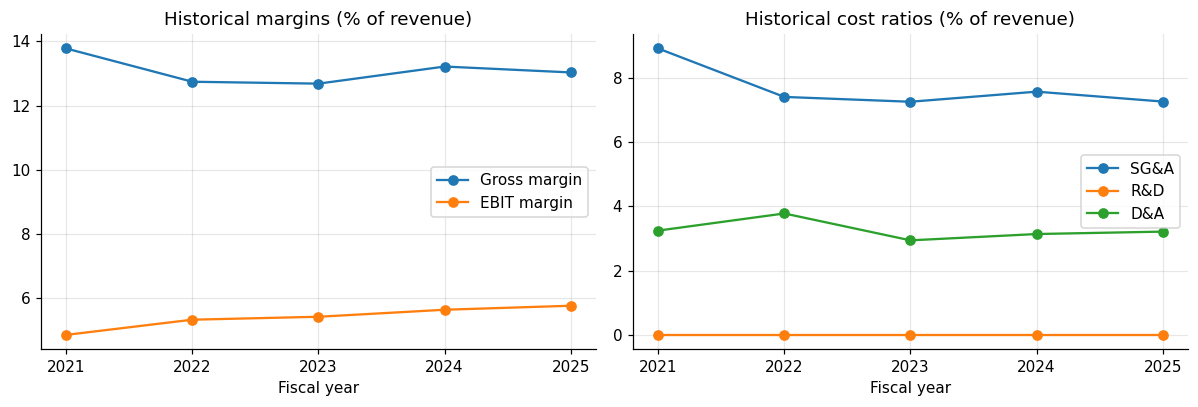

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
drivers[['gross_margin', 'ebit_margin']].rename(columns={
    'gross_margin': 'Gross margin', 'ebit_margin': 'EBIT margin'}).plot(ax=axes[0], marker='o')
drivers[['sga_pct', 'rnd_pct', 'da_pct_revenue']].rename(columns={
    'sga_pct': 'SG&A', 'rnd_pct': 'R&D', 'da_pct_revenue': 'D&A'}).plot(ax=axes[1], marker='o')
axes[0].set_title('Historical margins (% of revenue)')
axes[1].set_title('Historical cost ratios (% of revenue)')
for ax in axes:
    ax.set_xlabel('Fiscal year'); ax.set_xticks(hist.index); ax.grid(alpha=.3)
    ax.legend(loc='best')
plt.tight_layout(); plt.show()


### Quarterly view (provided)

Annual ratios can hide what the latest quarters show. This view uses `hist_q`: YoY growth versus the same quarter a year earlier, TTM revenue growth and margins, the seasonal share of fiscal-year revenue by quarter, and the latest TTM margins against the fiscal-year average. Use it as evidence for your assumptions (for example, whether the latest TTM margin argues for departing from the multi-year average).

,FY2020Q4,FY2021Q1,FY2021Q2,FY2021Q3,FY2021Q4,FY2022Q1,FY2022Q2,FY2022Q3,FY2022Q4,FY2023Q1,FY2023Q2,FY2023Q3,FY2023Q4,FY2024Q1,FY2024Q2,FY2024Q3,FY2024Q4,FY2025Q1,FY2025Q2,FY2025Q3,FY2025Q4,FY2026Q1,FY2026Q2,FY2026Q3
revenue,2912.2,2703.6,2999.8,3353.3,3923.5,3965.5,4232.0,4459.8,4416.6,4428.8,5048.6,5620.8,5783.9,5031.8,5594.4,6493.2,6553.4,6233.3,6773.0,7505.1,7840.0,7874.8,9557.0,12014.9
yoy_growth,NaN,NaN,NaN,NaN,34.7,46.7,41.1,33.0,12.6,11.7,19.3,26.0,31.0,13.6,10.8,15.5,13.3,23.9,21.1,15.6,19.6,26.3,41.1,60.1
gross_margin,15.3,13.0,14.2,15.3,12.7,10.9,12.2,13.9,13.7,11.3,13.0,13.8,12.4,10.9,13.1,13.9,14.5,11.6,13.2,14.5,12.6,14.1,16.2,16.7
ebit_margin,6.6,4.0,5.2,7.1,3.3,3.1,4.9,7.0,6.1,3.1,5.4,7.0,5.8,3.1,5.5,6.6,6.8,3.9,5.8,6.9,6.2,4.2,7.3,8.5
ttm_revenue,NaN,NaN,NaN,11968.9,12980.2,14242.2,15474.3,16580.8,17073.9,17537.2,18353.8,19514.9,20882.2,21485.2,22031.0,22903.3,23672.8,24874.3,26052.9,27064.9,28351.5,29992.9,32776.9,37286.7
ttm_growth,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.5,31.5,23.1,18.6,17.7,22.3,22.5,20.0,17.4,13.4,15.8,18.3,18.2,19.8,20.6,25.8,37.8
ttm_gross_margin,NaN,NaN,NaN,14.5,13.8,13.1,12.7,12.5,12.7,12.8,13.0,13.0,12.7,12.5,12.6,12.7,13.2,13.3,13.3,13.5,13.0,13.6,14.4,15.1
ttm_ebit_margin,NaN,NaN,NaN,5.8,4.9,4.5,4.5,4.7,5.3,5.3,5.4,5.5,5.4,5.4,5.4,5.4,5.6,5.7,5.8,5.9,5.8,5.8,6.2,6.8
ttm_etr,NaN,NaN,NaN,17.2,21.0,20.3,21.1,23.4,27.3,25.8,26.2,23.2,22.6,23.8,23.7,23.5,23.5,24.2,24.0,25.3,26.2,24.0,24.0,24.1


Share of fiscal-year revenue by fiscal quarter (%):


,mean,min,max
Q1,21.7,20.8,23.2
Q2,23.9,23.1,24.8
Q3,26.6,25.8,27.4
Q4,27.8,25.9,30.2


Latest TTM (FY2026Q3): gross margin 15.1% vs FY average 13.1%; EBIT margin 6.8% vs FY average 5.4%


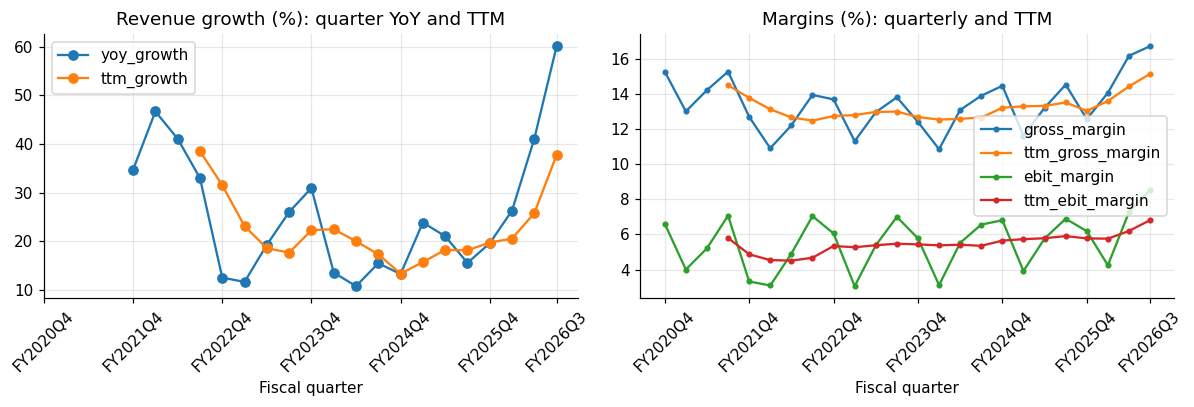

In [10]:
# Quarterly view (provided): computed from the raw quarterly lines, so it runs before your TODOs are done
qv = pd.DataFrame(index=hist_q.index)
qv["revenue"] = hist_q["revenue"]
qv["yoy_growth"] = hist_q["revenue"].pct_change(4) * 100                       # vs same quarter last year, %
qv["gross_margin"] = (hist_q["revenue"] - hist_q["cogs"]) / hist_q["revenue"] * 100
qv["ebit_margin"] = hist_q["ebit"] / hist_q["revenue"] * 100
qv["ttm_revenue"] = ttm(hist_q["revenue"])
qv["ttm_growth"] = qv["ttm_revenue"].pct_change(4) * 100
qv["ttm_gross_margin"] = (ttm(hist_q["revenue"]) - ttm(hist_q["cogs"])) / qv["ttm_revenue"] * 100
qv["ttm_ebit_margin"] = ttm(hist_q["ebit"]) / qv["ttm_revenue"] * 100
qv["ttm_etr"] = (ttm(hist_q["tax"]) / ttm(hist_q["ebt"]) * 100).where(ttm(hist_q["ebt"]) > 0)
display(qv.T.round(1))

# Seasonality: each quarter's share of its fiscal-year revenue (complete fiscal years only)
full_years = hist_q[hist_q["fiscal_year"].isin(hist.index)]
share = full_years["revenue"] / full_years.groupby("fiscal_year")["revenue"].transform("sum") * 100
seasonality = share.groupby(full_years["fiscal_q"]).agg(["mean", "min", "max"]).round(1)
seasonality.index = [f"Q{q}" for q in seasonality.index]
print("Share of fiscal-year revenue by fiscal quarter (%):"); display(seasonality)

# Latest TTM versus the fiscal-year average
fy_gm = (hist["revenue"] - hist["cogs"]) / hist["revenue"] * 100
fy_em = hist["ebit"] / hist["revenue"] * 100
latest = qv.dropna(subset=["ttm_revenue"]).iloc[-1]
print(f"Latest TTM ({qv.dropna(subset=['ttm_revenue']).index[-1]}): gross margin {latest['ttm_gross_margin']:.1f}% "
      f"vs FY average {fy_gm.mean():.1f}%; EBIT margin {latest['ttm_ebit_margin']:.1f}% vs FY average {fy_em.mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
qv[["yoy_growth", "ttm_growth"]].plot(ax=axes[0], marker="o", title="Revenue growth (%): quarter YoY and TTM")
qv[["gross_margin", "ttm_gross_margin", "ebit_margin", "ttm_ebit_margin"]].plot(ax=axes[1], marker=".", title="Margins (%): quarterly and TTM")
for ax in axes:
    ax.set_xlabel("Fiscal quarter"); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
positions = [i for i, label in enumerate(qv.index) if label.endswith('Q4')]
if len(qv) - 1 not in positions:
    positions.append(len(qv) - 1)
for ax in axes:
    ax.set_xticks(positions, [qv.index[i] for i in positions])
plt.tight_layout(); plt.show()


### Forecast assumptions (all forecast inputs live here)

Set each driver from the evidence above. Every assumption needs a one-line justification in the comment, tied to history or a disclosure (10-Q, 10-K, earnings call). Year 1 of the forecast is the fiscal year after the last complete fiscal year in `hist`.

- **Revenue (2.2):** growth by year, from a justified CAGR, a price × volume × mix view, or consensus.
- **COGS and operating expenses (2.3):** percent of revenue (or a gross margin target), with the driver behind any change.
- **D&A, interest, taxes (2.4):** D&A as a percent of revenue, checked against D&A ÷ prior-year PP&E so it reflects the asset base; net interest, stated as net or gross; and the normalized tax rate (from fiscal-year ETRs, not single quarters).

In [11]:
# ============== FORECAST ASSUMPTIONS ==============
SCENARIO = 'base'
MODEL_VERSION = '1.2'
GUIDANCE_FY = 2026
# Official October 29, 2026 outlook, p.2; guidance inputs, not historical overrides.
GUIDANCE_REVENUE_RANGE = (41300.0, 41600.0)
GUIDANCE_DA = 475.1 + 687.2       # Depreciation plus intangible amortization.
GUIDANCE_INTEREST_RANGE = (279.0, 284.0)
GUIDANCE_TAX_RANGE = (0.235, 0.237)
GUIDANCE_COMMON_NI_RANGE = (1920.0, 1980.0)
GUIDANCE_NCI_RANGE = (36.0, 40.0)

if int(hist.index[-1]) + 1 != GUIDANCE_FY:
    raise ValueError('Update dated guidance assumptions before forecasting a different first year.')
REVENUE_TARGET_Y1 = float(np.mean(GUIDANCE_REVENUE_RANGE))
REVENUE_GROWTH = [REVENUE_TARGET_Y1 / hist.revenue.iloc[-1] - 1, 0.15, 0.12, 0.10, 0.08]
# FY2026 = guidance midpoint. Yr 2 backed by $38.4B 12-month backlog (+72% YoY, Q3 commentary p.7);
# yrs 3-5 fade toward the 2026 Investor Day 7-10% organic CAGR; ~1-pt excess reflects acquisitions.
INVESTOR_DAY_ORGANIC_CAGR = (0.07, 0.10)  # 2026-2030 organic revenue CAGR target; excludes M&A.
COGS_PCT = 0.842          # 15.8% GM, close to 2026 YTD 15.83%; recent mix/execution supports reset.
SGA_PCT = 0.070           # 7.0%, near TTM 6.98% and YTD 7.14%; modest scale benefit, no further fade.
RND_PCT = 0.0             # No separately reported R&D in any of the 24 API quarters.
OTHER_OPEX_PCT = 0.0175   # Near YTD residual 1.71%; retains amortization and net other operating costs.
DA_PCT_REVENUE = GUIDANCE_DA / REVENUE_TARGET_Y1  # 2.80%; guidance and asset-footprint cross-check.
NET_INTEREST = float(np.mean(GUIDANCE_INTEREST_RANGE))  # Net expense, USD m; fixed financing scenario.
OTHER_NONOP = -30.0       # Net expense, near annualized 2026 YTD API residual of -30.2m.
TAX_EXCLUDE_YEARS = [2023] # 10-K Note 13: $20.177m valuation-allowance benefit (~2.08 ETR points).
TAX_RATE = normalized_tax_rate(hist, TAX_EXCLUDE_YEARS)
# 2024 restructuring benefit is only ~0.84 ETR points; recurring SBC benefits are not all removed.
# The exclusion rule targets the identified >1.5-point discrete valuation-allowance benefit.
TAX_SENSITIVITY_DELTA = 0.02

ytd = hist_q.loc[hist_q.fiscal_year.eq(GUIDANCE_FY)]
ytd_totals = ytd[FLOW_COLS + ['gross_profit', 'other_opex', 'other_nonop']].sum()
ttm_totals = hist_q.iloc[-4:][FLOW_COLS + ['gross_profit', 'other_opex', 'other_nonop']].sum()
revenue_cagr = (hist.revenue.iloc[-1] / hist.revenue.iloc[0]) ** (1 / (len(hist) - 1)) - 1
print('Forecast years:', list(range(GUIDANCE_FY, GUIDANCE_FY + FORECAST_YEARS)))
print('Revenue growth:', [f'{x:.2%}' for x in REVENUE_GROWTH])
print(f'Normalized annual ETR: {TAX_RATE:.2%}; excluded {TAX_EXCLUDE_YEARS}')


Forecast years: [2026, 2027, 2028, 2029, 2030]
Revenue growth: ['46.20%', '15.00%', '12.00%', '10.00%', '8.00%']
Normalized annual ETR: 24.84%; excluded [2023]


In [12]:
asset_check = pd.DataFrame({
    'D&A / revenue (%)': hist.da / hist.revenue * 100,
    'D&A / prior Q4 FMP PP&E (%)': drivers.da_pct_ppe,
    'D&A / prior Q4 PP&E + intangibles (%)': hist.da / (hist.ppe_net + hist.intangibles_net).shift(1) * 100})
display(asset_check.round(2))
display(Markdown(f"""
**Revenue.** [October 29 outlook, p.2]({OUTLOOK_URL}) gives $41.3–$41.6 billion for FY2026;
the midpoint is **{REVENUE_TARGET_Y1:,.0f}m**, or **{REVENUE_GROWTH[0]:.2%}** above the API FY2025 base.
The implied Q4 is {REVENUE_TARGET_Y1-ytd.revenue.sum():,.2f}m, compared with Q3
{hist_q.revenue.iloc[-1]:,.2f}m; this is a full-year estimate including reported YTD results,
not a second forecast layered on top of them. Latest TTM growth is {latest.ttm_growth:.2f}% versus
the complete-year CAGR of {revenue_cagr:.2%}. The [Q3 commentary, p.2]({COMMENTARY_URL}) separates
YTD reported growth of 42.7% from organic growth of 26.8%; acquisitions must not be labeled organic.
Years 2–5 use 15%, 12%, 10%, and 8%. Backlog supports year 2: at September 30, 2026 the
[Q3 commentary, p.7]({COMMENTARY_URL}) reports record total backlog of $63.7 billion (+62.7% YoY,
including about $1.3 billion acquired) and 12-month backlog of $38.4 billion (+72.3% YoY), already
above company-reported trailing-twelve-month revenue of about $37.3 billion. Management also expects
"strong double-digit adjusted EPS growth in 2027" ([Q3 release]({RELEASE_URL})). Growth then fades
toward the [2026 Investor Day]({INVESTOR_DAY_URL}) organic target of a
{INVESTOR_DAY_ORGANIC_CAGR[0]:.0%}–{INVESTOR_DAY_ORGANIC_CAGR[1]:.0%} 2026–2030 revenue CAGR. This
forecast's FY2026–FY2030 CAGR is {np.prod([1+g for g in REVENUE_GROWTH[1:]])**(1/(FORECAST_YEARS-1))-1:.1%},
about one point above that organic range. The gap reflects Quanta's continuing acquisition program
(about $3.28 billion of acquired revenue YTD 2026, [Q3 commentary, p.19]({COMMENTARY_URL})), which the
organic target excludes. Applying the target range to the {REVENUE_TARGET_Y1:,.0f}m FY2026 base implies
FY2030 revenue of {REVENUE_TARGET_Y1*(1+INVESTOR_DAY_ORGANIC_CAGR[0])**(FORECAST_YEARS-1):,.0f}–{REVENUE_TARGET_Y1*(1+INVESTOR_DAY_ORGANIC_CAGR[1])**(FORECAST_YEARS-1):,.0f}m
versus {REVENUE_TARGET_Y1*np.prod([1+g for g in REVENUE_GROWTH[1:]]):,.0f}m here, so the years 3–5 growth
rates are the main revenue assumption to revisit.
Historically, {seasonality['mean'].idxmax()} has the largest average share of annual revenue
({seasonality['mean'].max():.1f}%); Q4 averages {seasonality.loc['Q4','mean']:.1f}%.
The guidance-based implied FY2026 Q4 share is
{(REVENUE_TARGET_Y1-ytd.revenue.sum())/REVENUE_TARGET_Y1:.1%}, a seasonality sanity check rather
than an assumption that every future quarter has the same seasonal weight.

**Costs.** Forecast gross margin is {1-COGS_PCT:.1%}, close to YTD
{ytd_totals.gross_profit/ytd_totals.revenue:.2%}; TTM gross margin is {latest.ttm_gross_margin:.2f}%
versus the annual average {drivers.gross_margin.mean():.2f}%. Better execution and mix support some
improvement, but FMP reclassification also changes gross margin, so the entire gap is not efficiency.
SG&A at {SGA_PCT:.1%} is near TTM {ttm_totals.sga/ttm_totals.revenue:.2%} and YTD
{ytd_totals.sga/ytd_totals.revenue:.2%}. Other OpEx at {OTHER_OPEX_PCT:.2%} is anchored to YTD
{ytd_totals.other_opex/ytd_totals.revenue:.2%}, rather than the near-zero older residual.
The [Q3 release]({RELEASE_URL}) shows this category includes amortization and contingent
consideration costs net of integral affiliate earnings. R&D stays zero because no separate line is
reported; it does not assert that Quanta spends nothing on technology. The resulting EBIT margin
is {1-COGS_PCT-SGA_PCT-RND_PCT-OTHER_OPEX_PCT:.2%}, versus latest TTM {latest.ttm_ebit_margin:.2f}%.

**D&A.** Guidance depreciation plus intangible amortization is {GUIDANCE_DA:,.1f}m, implying
{DA_PCT_REVENUE:.2%} of revenue. This is {GUIDANCE_DA/hist.ppe_net.iloc[-1]:.2%} of prior Q4 FMP PP&E,
compared with FY2025 {drivers.da_pct_ppe.iloc[-1]:.2f}%, and
{GUIDANCE_DA/(hist.ppe_net.iloc[-1]+hist.intangibles_net.iloc[-1]):.2%} of PP&E plus intangibles.
The high PP&E-only ratio reflects substantial acquired-intangible amortization and the broader
FMP PP&E definition; it is not a depreciation rate or useful-life estimate. A constant sales ratio
assumes the amortizable asset footprint scales with sales; no separate acquisition or PP&E schedule
is forecast. D&A is added back only for EBITDA, since operating costs already include it.

**Interest and other items.** Net interest expense is {NET_INTEREST:,.1f}m, the guidance midpoint,
versus latest TTM {ttm_totals.interest_expense-ttm_totals.interest_income:,.1f}m. Holding it fixed
assumes stable net financing costs, not debt proportional to sales. Other non-operating expense
is {-OTHER_NONOP:,.1f}m, close to the annualized YTD API residual
{-ytd_totals.other_nonop * 4 / len(ytd):,.1f}m. Investment gains and acquisition funding can change both.

**Tax.** The normalized rate is {TAX_RATE:.2%}, the median annual ETR excluding FY2023.
[FY2025 10-K Note 13]({TEN_K_URL}) identifies a FY2023 valuation-allowance benefit of $20.177m,
about 2.08 percentage points of that year's EBT. This exceeds the stated 1.5-point discrete-item
screen; FY2024's restructuring benefit of about 0.84 points does not. Recurring stock-compensation
benefits remain. The result is more conservative than management's FY2026 23.5%–23.7% expectation;
the sensitivity tests {TAX_RATE-TAX_SENSITIVITY_DELTA:.2%} and {TAX_RATE+TAX_SENSITIVITY_DELTA:.2%}.
Management's {np.mean(GUIDANCE_TAX_RANGE):.1%} midpoint falls inside that band, and applying it to FY2026
would raise net income by roughly 1.6%, still inside the guidance envelope (quantified in Section 2.6).
One guided year's rate is not used for all five years because it can include that year's discrete
items; the median of complete fiscal years is the steady-state assumption.
The tax calculation uses FMP annual aggregates; disclosures support the documented exclusion.
"""))


,D&A / revenue (%),D&A / prior Q4 FMP PP&E (%),D&A / prior Q4 PP&E + intangibles (%)
fiscal_year,,,
2021,3.24,NaN,NaN
2022,3.78,29.84,16.27
2023,2.94,27.16,16.51
2024,3.14,28.70,18.80
2025,3.21,30.34,18.73



**Revenue.** [October 29 outlook, p.2](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/outlook_expectations_summary/PWR_09-30-2026_Outlook_Expectations_Summary.pdf) gives $41.3–$41.6 billion for FY2026;
the midpoint is **41,450m**, or **46.20%** above the API FY2025 base.
The implied Q4 is 12,003.34m, compared with Q3
12,014.88m; this is a full-year estimate including reported YTD results,
not a second forecast layered on top of them. Latest TTM growth is 37.77% versus
the complete-year CAGR of 21.57%. The [Q3 commentary, p.2](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/operational_and_financial_commentary/PWR_09-30-2026_ER_Operational_and_Financial_Summary.pdf) separates
YTD reported growth of 42.7% from organic growth of 26.8%; acquisitions must not be labeled organic.
Years 2–5 use 15%, 12%, 10%, and 8%. Backlog supports year 2: at September 30, 2026 the
[Q3 commentary, p.7](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/operational_and_financial_commentary/PWR_09-30-2026_ER_Operational_and_Financial_Summary.pdf) reports record total backlog of $63.7 billion (+62.7% YoY,
including about $1.3 billion acquired) and 12-month backlog of $38.4 billion (+72.3% YoY), already
above company-reported trailing-twelve-month revenue of about $37.3 billion. Management also expects
"strong double-digit adjusted EPS growth in 2027" ([Q3 release](https://investors.quantaservices.com/news-events/press-releases/detail/407/quanta-services-reports-third-quarter-2026-results)). Growth then fades
toward the [2026 Investor Day](https://investors.quantaservices.com/_assets/_33a741543a242bab3497a25a8c07419a/quantaservices/db/894/10451/pdf/Quanta+Services+2026+Investor+Day+Presentation+vF+for+Website.pdf) organic target of a
7%–10% 2026–2030 revenue CAGR. This
forecast's FY2026–FY2030 CAGR is 11.2%,
about one point above that organic range. The gap reflects Quanta's continuing acquisition program
(about $3.28 billion of acquired revenue YTD 2026, [Q3 commentary, p.19](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/operational_and_financial_commentary/PWR_09-30-2026_ER_Operational_and_Financial_Summary.pdf)), which the
organic target excludes. Applying the target range to the 41,450m FY2026 base implies
FY2030 revenue of 54,332–60,687m
versus 63,424m here, so the years 3–5 growth
rates are the main revenue assumption to revisit.
Historically, Q4 has the largest average share of annual revenue
(27.8%); Q4 averages 27.8%.
The guidance-based implied FY2026 Q4 share is
29.0%, a seasonality sanity check rather
than an assumption that every future quarter has the same seasonal weight.

**Costs.** Forecast gross margin is 15.8%, close to YTD
15.83%; TTM gross margin is 15.14%
versus the annual average 13.09%. Better execution and mix support some
improvement, but FMP reclassification also changes gross margin, so the entire gap is not efficiency.
SG&A at 7.0% is near TTM 6.98% and YTD
7.14%. Other OpEx at 1.75% is anchored to YTD
1.71%, rather than the near-zero older residual.
The [Q3 release](https://investors.quantaservices.com/news-events/press-releases/detail/407/quanta-services-reports-third-quarter-2026-results) shows this category includes amortization and contingent
consideration costs net of integral affiliate earnings. R&D stays zero because no separate line is
reported; it does not assert that Quanta spends nothing on technology. The resulting EBIT margin
is 7.05%, versus latest TTM 6.81%.

**D&A.** Guidance depreciation plus intangible amortization is 1,162.3m, implying
2.80% of revenue. This is 30.14% of prior Q4 FMP PP&E,
compared with FY2025 30.34%, and
17.19% of PP&E plus intangibles.
The high PP&E-only ratio reflects substantial acquired-intangible amortization and the broader
FMP PP&E definition; it is not a depreciation rate or useful-life estimate. A constant sales ratio
assumes the amortizable asset footprint scales with sales; no separate acquisition or PP&E schedule
is forecast. D&A is added back only for EBITDA, since operating costs already include it.

**Interest and other items.** Net interest expense is 281.5m, the guidance midpoint,
versus latest TTM 286.3m. Holding it fixed
assumes stable net financing costs, not debt proportional to sales. Other non-operating expense
is 30.0m, close to the annualized YTD API residual
30.2m. Investment gains and acquisition funding can change both.

**Tax.** The normalized rate is 24.84%, the median annual ETR excluding FY2023.
[FY2025 10-K Note 13](https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-26-000006/pwr-20251231.htm) identifies a FY2023 valuation-allowance benefit of $20.177m,
about 2.08 percentage points of that year's EBT. This exceeds the stated 1.5-point discrete-item
screen; FY2024's restructuring benefit of about 0.84 points does not. Recurring stock-compensation
benefits remain. The result is more conservative than management's FY2026 23.5%–23.7% expectation;
the sensitivity tests 22.84% and 26.84%.
Management's 23.6% midpoint falls inside that band, and applying it to FY2026
would raise net income by roughly 1.6%, still inside the guidance envelope (quantified in Section 2.6).
One guided year's rate is not used for all five years because it can include that year's discrete
items; the median of complete fiscal years is the steady-state assumption.
The tax calculation uses FMP annual aggregates; disclosures support the documented exclusion.


### Contract liabilities / deferred revenue

Quanta performs infrastructure construction and maintenance rather than selling software subscriptions.
Because it does bill in advance under some contracts, a historical bridge is included rather than simply
marking this section inapplicable. FMP `deferredRevenue` corresponds to contract liabilities in the
FY2025 balance sheet. It is not backlog or a forecast of all future revenue.

The available API does not separately identify gross advance billings, revenue released from
each contract-liability cohort, acquisitions, and currency effects. The simplified bridge therefore
labels **billings-equivalent additions as implied**, using revenue + change in contract liabilities.
It proves the accounting identity, not actual cash collections or independently observed billings.
Acquisitions and contract assets limit its interpretation; the exact gross operating roll-forward
cannot be recovered from these fields alone.


In [13]:
# Use FY2020Q4 to supply the opening stock for the first complete historical year.
q4_liabilities = hist_q.loc[hist_q.fiscal_q.eq(4)].set_index('fiscal_year').deferred_revenue
deferred_bridge = pd.DataFrame(index=hist.index)
deferred_bridge['beginning'] = pd.Series({y: q4_liabilities.get(y-1, np.nan) for y in hist.index})
deferred_bridge['revenue_recognized_proxy'] = hist.revenue
deferred_bridge['ending'] = hist.deferred_revenue
deferred_bridge['implied_billings_equivalent'] = (
    deferred_bridge.revenue_recognized_proxy + deferred_bridge.ending - deferred_bridge.beginning)
deferred_bridge['recomputed_ending'] = (deferred_bridge.beginning
    + deferred_bridge.implied_billings_equivalent - deferred_bridge.revenue_recognized_proxy)
deferred_bridge['change'] = deferred_bridge.ending - deferred_bridge.beginning
display(deferred_bridge[['beginning', 'implied_billings_equivalent', 'revenue_recognized_proxy',
                         'ending', 'recomputed_ending', 'change']].round(2))
display(Markdown(f"""**Interpretation.** Contract liabilities rise from
{deferred_bridge.beginning.iloc[0]:,.1f}m at the opening of FY2021 to
{deferred_bridge.ending.iloc[-1]:,.1f}m at FY2025 year-end. In FY2025, the increase is
{deferred_bridge.change.iloc[-1]:,.1f}m. The [10-K Note 4]({TEN_K_URL}) attributes the increase to
acquisitions and favorable billing terms and reports $1.98 billion of FY2025 revenue recognized
from opening contract liabilities. This supports evidence of advance-funded work, but does not
justify applying the liability growth rate to revenue. The first forecast year is anchored to
current revenue guidance; later growth rates taper. The table's total-revenue proxy is broader
than revenue released from opening liabilities, and its implied additions include unseparated
acquisition/other changes. An exact billings forecast would require contract-level data."""))


,beginning,implied_billings_equivalent,revenue_recognized_proxy,ending,recomputed_ending,change
fiscal_year,,,,,,
2021,528.86,13254.22,12980.21,802.87,802.87,274.01
2022,802.87,17412.55,17073.90,1141.52,1141.52,338.65
2023,1141.52,21279.36,20882.21,1538.68,1538.68,397.16
2024,1538.68,24283.45,23672.80,2149.33,2149.33,610.65
2025,2149.33,29460.62,28351.48,3258.46,3258.46,1109.14


**Interpretation.** Contract liabilities rise from
528.9m at the opening of FY2021 to
3,258.5m at FY2025 year-end. In FY2025, the increase is
1,109.1m. The [10-K Note 4](https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-26-000006/pwr-20251231.htm) attributes the increase to
acquisitions and favorable billing terms and reports $1.98 billion of FY2025 revenue recognized
from opening contract liabilities. This supports evidence of advance-funded work, but does not
justify applying the liability growth rate to revenue. The first forecast year is anchored to
current revenue guidance; later growth rates taper. The table's total-revenue proxy is broader
than revenue released from opening liabilities, and its implied additions include unseparated
acquisition/other changes. An exact billings forecast would require contract-level data.

---
## 2.5 Statement Assembly

Write `forecast_income_statement()`. It must compute every line with deterministic formulas, in this order:
Revenue → COGS → **Gross Profit** → SG&A, R&D, Other OpEx → **EBIT** → D&A → **EBITDA = EBIT + D&A** → Net Interest, Other Non-Op → **EBT** → Tax → **Net Income**.

In [14]:
LINES = ['revenue', 'cogs', 'gross_profit', 'sga', 'rnd', 'other_opex', 'ebit', 'da', 'ebitda',
         'net_interest', 'other_nonop', 'ebt', 'tax', 'net_income']

def forecast_income_statement(last_revenue, first_year, growth, cogs_pct, sga_pct, rnd_pct,
                              other_pct, da_pct, net_interest, other_nonop, tax_rate):
    """Annual driver model, with consolidated net income and no tax benefit on losses."""
    growth = np.asarray(growth, dtype=float)
    costs = np.asarray([cogs_pct, sga_pct, rnd_pct, other_pct, da_pct], dtype=float)
    if growth.ndim != 1 or not len(growth) or not np.isfinite(growth).all() or (growth <= -1).any():
        raise ValueError('Growth must be a nonempty finite vector with each value > -100%.')
    if not np.isfinite(last_revenue) or last_revenue <= 0:
        raise ValueError('Starting revenue must be positive.')
    if not np.isfinite(costs).all() or (costs < 0).any() or (costs > 1).any():
        raise ValueError('Forecast cost ratios must be finite decimals between zero and one.')
    if not np.isfinite([net_interest, other_nonop, tax_rate]).all() or not 0 <= tax_rate <= 1:
        raise ValueError('Invalid interest, other income, or tax rate.')
    rows = {}
    revenue = float(last_revenue)
    for i, g in enumerate(growth):
        year = int(first_year) + i
        revenue *= 1 + g
        cogs = revenue * cogs_pct
        gross_profit = revenue - cogs
        sga, rnd, other_opex = revenue * sga_pct, revenue * rnd_pct, revenue * other_pct
        ebit = gross_profit - sga - rnd - other_opex
        da = revenue * da_pct
        ebitda = ebit + da
        ebt = ebit - net_interest + other_nonop
        tax = max(ebt, 0) * tax_rate
        rows[year] = dict(zip(LINES, [revenue, cogs, gross_profit, sga, rnd, other_opex,
            ebit, da, ebitda, net_interest, other_nonop, ebt, tax, ebt - tax]))
    out = pd.DataFrame.from_dict(rows, orient='index')[LINES]
    out.index.name = 'fiscal_year'
    return out

def run_forecast(tax_rate=TAX_RATE):
    return forecast_income_statement(hist.revenue.iloc[-1], int(hist.index[-1]) + 1,
        REVENUE_GROWTH, COGS_PCT, SGA_PCT, RND_PCT, OTHER_OPEX_PCT,
        DA_PCT_REVENUE, NET_INTEREST, OTHER_NONOP, tax_rate)

forecast = run_forecast()


In [15]:
# Combined statement (provided): actuals "A" and forecasts "E" clearly labeled
combined = pd.concat([hist[LINES], forecast])
combined.index = [f"FY{y}{'A' if y <= hist.index[-1] else 'E'}" for y in combined.index]
display(combined.T.round(1))

,FY2021A,FY2022A,FY2023A,FY2024A,FY2025A,FY2026E,FY2027E,FY2028E,FY2029E,FY2030E
revenue,12980.2,17073.9,20882.2,23672.8,28351.5,41450.0,47667.5,53387.6,58726.4,63424.5
cogs,11192.3,14898.7,18234.1,20545.0,24657.4,34900.9,40136.0,44952.4,49447.6,53403.4
gross_profit,1787.9,2175.2,2648.1,3127.8,3694.0,6549.1,7531.5,8435.2,9278.8,10021.1
sga,1156.0,1263.4,1513.8,1790.4,2056.9,2901.5,3336.7,3737.1,4110.8,4439.7
rnd,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
other_opex,-0.0,0.0,0.0,-0.0,0.0,725.4,834.2,934.3,1027.7,1109.9
ebit,631.9,911.8,1134.3,1337.4,1637.1,2922.2,3360.6,3763.8,4140.2,4471.4
da,420.9,644.6,613.8,742.3,910.3,1162.3,1336.6,1497.0,1646.7,1778.5
ebitda,1052.8,1556.4,1748.1,2079.7,2547.5,4084.5,4697.2,5260.9,5787.0,6249.9
net_interest,65.7,121.8,176.1,170.3,245.7,281.5,281.5,281.5,281.5,281.5


**Tax sensitivity (±2 percentage points).** Re-run the forecast with the tax rate 2 points lower and higher, and compare net income.

In [16]:
tax_sensitivity = pd.DataFrame({
    f'Low tax ({TAX_RATE-TAX_SENSITIVITY_DELTA:.2%})': run_forecast(TAX_RATE-TAX_SENSITIVITY_DELTA).net_income,
    f'Base ({TAX_RATE:.2%})': forecast.net_income,
    f'High tax ({TAX_RATE+TAX_SENSITIVITY_DELTA:.2%})': run_forecast(TAX_RATE+TAX_SENSITIVITY_DELTA).net_income,
})
display(tax_sensitivity.round(2))
display(Markdown(f'Year-five net income moves by **±{forecast.ebt.iloc[-1]*TAX_SENSITIVITY_DELTA:,.2f}m** '
                 'because each two-point rate change applies to the same positive pretax income.'))


,Low tax (22.84%),Base (24.84%),High tax (26.84%)
fiscal_year,,,
2026,2014.55,1962.34,1910.12
2027,2352.79,2291.81,2230.83
2028,2663.97,2594.92,2525.87
2029,2954.40,2877.83,2801.25
2030,3209.98,3126.78,3043.58


Year-five net income moves by **±83.20m** because each two-point rate change applies to the same positive pretax income.

---
## 2.6 Validation Checks

`check()` records each test as PASS or FAIL across historical and forecast years. Write the checks from the brief, using thresholds you justify. Two quarterly data checks are provided: **quarterly coverage** (at least 20 unique, consecutive quarters) and the **quarter-to-annual tie-out** (the four quarters of the latest complete fiscal year sum to the 10-K revenue within 0.5%). The other checks run on the annual table.

In [17]:
checks = []
def check(name, passed, detail=''):
    checks.append({'check': name, 'result': 'PASS' if bool(passed) else 'FAIL', 'detail': detail})

full = pd.concat([hist[LINES], forecast])
gm = full.gross_profit / full.revenue * 1e4
sga_bps = full.sga / full.revenue * 1e4
ok, detail = check_quarters(hist_q)
check('Quarterly coverage', ok, detail)
annual_is = fmp_get('income-statement', SYMBOL, period='annual', limit=ANNUAL_LIMIT)
fy_last = int(hist.index[-1])
match = annual_is.loc[annual_is.fiscalYear.astype(int).eq(fy_last)]
if len(match) != 1:
    check('Quarter-to-annual revenue tie-out', False, f'Expected one annual record for FY{fy_last}')
else:
    annual_rev = float(match.iloc[0].revenue) / SCALE
    gap = abs(hist.loc[fy_last, 'revenue'] / annual_rev - 1)
    check('Quarter-to-annual revenue tie-out', gap <= CHECK_LIMITS['annual_tie_relative'],
          f'FY{fy_last}: quarters {hist.loc[fy_last,"revenue"]:,.3f}; FMP annual {annual_rev:,.3f}; gap {gap:.3%}')

def drift_check(name, series, limit):
    delta = series.diff().dropna()
    bad = delta[delta.abs() > limit]
    check(name, bad.empty, '; '.join(f'FY{y}: {v:+.1f} bps' for y,v in bad.items()) or 'No breaches')
drift_check('Gross margin drift >150 bps', gm, CHECK_LIMITS['gm_bps'])
drift_check('SG&A share shift >100 bps', sga_bps, CHECK_LIMITS['sga_bps'])
growth_tables = {}
for field, bound_key in [('revenue', 'revenue_growth'), ('net_income', 'net_income_growth')]:
    previous = full[field].shift(1)
    growth = (full[field] / previous - 1).where(previous > 0)
    growth_tables[field] = growth
    lower, upper = CHECK_LIMITS[bound_key]
    invalid = previous.iloc[1:].le(0)
    bad = growth[(growth < lower) | (growth > upper)]
    detail = '; '.join(f'FY{y}: {v:.1%}' for y,v in bad.items())
    if invalid.any():
        detail += '; nonpositive growth base: ' + ', '.join(map(str, invalid[invalid].index))
    check(f'{field} growth outliers', bad.empty and not invalid.any(), detail or 'Within stated bounds')
etr_full = (full.tax / full.ebt).where(full.ebt > 0)
lo, hi = CHECK_LIMITS['etr']
bad_etr = etr_full.dropna()[~etr_full.dropna().between(lo, hi)]
check('Annual ETR plausibility', bad_etr.empty, f'Bounds {lo:.0%}–{hi:.0%}; positive-EBT years only; '
      + ('; '.join(f'FY{y}: {v:.2%}' for y,v in bad_etr.items()) or 'No breaches'))
check('Annual index and EBIT integrity', full.index.is_unique and full.index.is_monotonic_increasing
      and np.all(np.diff(full.index) == 1) and full.ebit.le(full.revenue).all(),
      'Unique consecutive increasing fiscal years; EBIT <= revenue')
check('Finite values and core signs', np.isfinite(full.to_numpy()).all()
      and full.revenue.gt(0).all() and full[['cogs','sga','rnd','da']].ge(0).all().all(),
      'Core expenses nonnegative; signed other OpEx/non-Op and historical tax benefits permitted')
residuals = pd.DataFrame({
    'GP': full.gross_profit - (full.revenue - full.cogs),
    'EBIT': full.ebit - (full.gross_profit-full.sga-full.rnd-full.other_opex),
    'EBITDA': full.ebitda - (full.ebit+full.da),
    'EBT': full.ebt - (full.ebit-full.net_interest+full.other_nonop),
    'NI': full.net_income - (full.ebt-full.tax),
})
check('Statement identities, all years', residuals.abs().max().max() <= CHECK_LIMITS['identity_abs'],
      f'Maximum absolute residual {residuals.abs().max().max():.8f}m')
check('D&A cash-flow / income cross-check', np.allclose(hist_q.da.to_numpy(),
      raw_income.depreciationAndAmortization.to_numpy()/SCALE, atol=CHECK_LIMITS['identity_abs'], rtol=0),
      'All 24 quarters; cash-flow D&A matches income endpoint D&A')
check('Deferred-revenue bridge identity', np.isfinite(deferred_bridge.to_numpy()).all()
      and np.allclose(deferred_bridge.recomputed_ending, deferred_bridge.ending),
      'Implied billings-equivalent, not independently disclosed billings')
check('First-year revenue guidance and reported YTD',
      GUIDANCE_REVENUE_RANGE[0] <= forecast.revenue.iloc[0] <= GUIDANCE_REVENUE_RANGE[1]
      and forecast.revenue.iloc[0] > ytd.revenue.sum(),
      f'FY2026 {forecast.revenue.iloc[0]:,.1f}m; implied Q4 {forecast.revenue.iloc[0]-ytd.revenue.sum():,.1f}m')
check('Tax sensitivity arithmetic',
      np.allclose(tax_sensitivity.iloc[:,0]-forecast.net_income, forecast.ebt.clip(lower=0)*TAX_SENSITIVITY_DELTA)
      and np.allclose(forecast.net_income-tax_sensitivity.iloc[:,2], forecast.ebt.clip(lower=0)*TAX_SENSITIVITY_DELTA),
      'Each +/-2 point rate move changes NI by -/+2% of positive EBT')

# Preserve PASS/FAIL results while distinguishing integrity from economic screens.
trend_checks = {'Gross margin drift >150 bps', 'SG&A share shift >100 bps',
                'revenue growth outliers', 'net_income growth outliers', 'Annual ETR plausibility'}
for item in checks:
    item['category'] = ('Economic diagnostic' if item['check'] in trend_checks else 'Mechanical integrity')
checks_df = pd.DataFrame(checks)[['category', 'check', 'result', 'detail']]
validation_overview = pd.crosstab(checks_df.category, checks_df.result).reindex(columns=['PASS','FAIL'], fill_value=0)
display(validation_overview)
display(checks_df)
display(Markdown('**Reading these results:** FMP is the required historical source. '
    'Mechanical checks test calculations and data structure; economic diagnostics identify unusual changes. '
    'Agreement with SEC figures is not part of this validation. '
    'Trend-screen thresholds and their flagged results are unchanged.'))


income-statement: 5 annual records through 2025-12-31


result,PASS,FAIL
category,,
Economic diagnostic,1,4
Mechanical integrity,9,0


,category,check,result,detail
0,Mechanical integrity,Quarterly coverage,PASS,24 quarters (FY2020Q4 to FY2026Q3); unique=True; consecutive=True
1,Mechanical integrity,Quarter-to-annual revenue tie-out,PASS,"FY2025: quarters 28,351.482; FMP annual 28,351.482; gap 0.000%"
2,Economic diagnostic,Gross margin drift >150 bps,FAIL,FY2026: +277.1 bps
3,Economic diagnostic,SG&A share shift >100 bps,FAIL,FY2022: -150.6 bps
4,Economic diagnostic,revenue growth outliers,FAIL,FY2022: 31.5%; FY2026: 46.2%
5,Economic diagnostic,net_income growth outliers,FAIL,FY2023: 46.7%; FY2026: 88.5%
6,Economic diagnostic,Annual ETR plausibility,PASS,Bounds 10%–35%; positive-EBT years only; No breaches
7,Mechanical integrity,Annual index and EBIT integrity,PASS,Unique consecutive increasing fiscal years; EBIT <= revenue
8,Mechanical integrity,Finite values and core signs,PASS,Core expenses nonnegative; signed other OpEx/non-Op and historical tax benefits permitted
9,Mechanical integrity,"Statement identities, all years",PASS,Maximum absolute residual 0.00000000m


**Reading these results:** FMP is the required historical source. Mechanical checks test calculations and data structure; economic diagnostics identify unusual changes. Agreement with SEC figures is not part of this validation. Trend-screen thresholds and their flagged results are unchanged.

In [18]:
ni_guidance_envelope = (GUIDANCE_COMMON_NI_RANGE[0]+GUIDANCE_NCI_RANGE[0],
                        GUIDANCE_COMMON_NI_RANGE[1]+GUIDANCE_NCI_RANGE[1])
display(Markdown(f"""**Evidence for the earnings-growth flag.** FY2026 consolidated forecast
net income is **{forecast.net_income.iloc[0]:,.2f}m**. The outlook's common-stock income range
plus the NCI range gives an approximate consolidated income envelope of
**{ni_guidance_envelope[0]:,.0f}–{ni_guidance_envelope[1]:,.0f}m**. The forecast lies within that
envelope, supporting the large growth assumption even though it triggers the historical-growth
screen. Historical values remain sourced from FMP."""))

gm_moves = gm.loc[hist.index].diff().dropna()
sga_moves = sga_bps.loc[hist.index].diff().dropna()
failed_names = checks_df.loc[checks_df.result.eq('FAIL'), 'check'].tolist()
display(Markdown(f"""
**Flagged periods ({len(failed_names)} of {len(checks)} checks).** A FAIL is an investigation flag;
it is not hidden or turned into a PASS by widening thresholds after seeing results.

- **FY2026 gross-margin drift, {gm.loc[2026]-gm.loc[2025]:+.1f} bps (data issue + assumption to revisit).**
  About {(OTHER_OPEX_PCT - hist.other_opex.iloc[-1]/hist.revenue.iloc[-1])*1e4:.0f} bps of the jump is
  classification: FMP's 2026 presentation moves amortization and other operating items out of COGS into
  other OpEx (about 0% of revenue in FY2021–FY2025, {ytd_totals.other_opex/ytd_totals.revenue:.2%} YTD,
  {OTHER_OPEX_PCT:.2%} forecast). Net of that and a lower SG&A ratio, EBIT margin rises only
  {(forecast.ebit.iloc[0]/forecast.revenue.iloc[0] - hist.ebit.iloc[-1]/hist.revenue.iloc[-1])*1e4:.0f} bps
  ({hist.ebit.iloc[-1]/hist.revenue.iloc[-1]:.2%} to {forecast.ebit.iloc[0]/forecast.revenue.iloc[0]:.2%}),
  consistent with the latest TTM EBIT margin of {latest.ttm_ebit_margin:.1f}%. The {1-COGS_PCT:.1%}
  gross-margin level should be revisited if YTD margins fade.
- **FY2022 SG&A share, {sga_bps.loc[2022]-sga_bps.loc[2021]:+.1f} bps (economic event).** Revenue grew
  {growth_tables['revenue'].loc[2022]:.1%} in the first full year after the
  [Blattner acquisition]({BLATTNER_URL}) while SG&A grew {hist.sga.loc[2022]/hist.sga.loc[2021]-1:.1%},
  so the ratio fell through scale, not a cut in spending.
- **FY2022 revenue growth, {growth_tables['revenue'].loc[2022]:.1%} (economic event).** The same Blattner
  acquisition effect; not a data error.
- **FY2023 net-income growth, {growth_tables['net_income'].loc[2023]:.1%} (economic event).** The FY2022
  base was depressed by net other non-operating expense of {-hist.other_nonop.loc[2022]:,.1f}m, which became
  {hist.other_nonop.loc[2023]:,.1f}m of income in FY2023, plus the $20.177m FY2023 valuation-allowance
  tax benefit. EBIT itself grew a more normal {hist.ebit.loc[2023]/hist.ebit.loc[2022]-1:.1%}.
- **FY2026 revenue growth, {growth_tables['revenue'].loc[2026]:.1%} (economic event).** This is the
  guidance midpoint; YTD reported growth of 42.7% splits into 26.8% organic growth plus about
  $3.28 billion of acquired revenue ([Q3 commentary, p.19]({COMMENTARY_URL})).
- **FY2026 net-income growth, {growth_tables['net_income'].loc[2026]:.1%} (assumption to revisit,
  cross-checked).** It follows from guidance revenue plus the margin reset. Forecast net income lies inside
  the {ni_guidance_envelope[0]:,.0f}–{ni_guidance_envelope[1]:,.0f}m guidance envelope; at the guided
  {np.mean(GUIDANCE_TAX_RANGE):.1%} tax rate it would be {forecast.ebt.iloc[0]*(1-np.mean(GUIDANCE_TAX_RANGE)):,.1f}m
  ({forecast.ebt.iloc[0]*(1-np.mean(GUIDANCE_TAX_RANGE))/forecast.net_income.iloc[0]-1:+.1%}), also inside it.

**Threshold basis.** Historical year-to-year gross-margin moves reach at most
{gm_moves.abs().max():.0f} bps (median {gm_moves.abs().median():.0f} bps), so 150 bps flags only unusual
shifts. Excluding FY2022, SG&A moves are at most {sga_moves.drop(2022).abs().max():.0f} bps, so 100 bps is
more than three times a typical move. Revenue bounds of -10% to +30% bracket FY2023–FY2025 growth of
{drivers.revenue_growth.loc[2023:2025].min():.1f}%–{drivers.revenue_growth.loc[2023:2025].max():.1f}%;
net-income bounds are wider (-30% to +40%) because operating and financial leverage make earnings more
volatile than sales. Execution and acquisition integration remain the main reasons the forecast might fail.

**ETR bounds:** 10%–35% are diagnostic, not statutory limits. They surround observed annual rates
and the outlook; tax benefits can make individual quarters fall outside them. Only positive-EBT
annual periods are evaluated. All mechanical identity, coverage, and sensitivity checks must pass.
**Checks currently flagged:** {', '.join(failed_names) or 'none'}.
"""))

# Small behavioral checks: compounding, no tax benefit on losses, and loss-year ETR exclusion.
toy = forecast_income_statement(100, 2030, [0.10, 0.20], .5, .1, 0, 0, .05, 0, 0, .25)
assert np.allclose(toy.revenue, [110, 132])
loss_case = forecast_income_statement(100, 2030, [0], .8, .3, 0, 0, .05, 0, 0, .25)
assert loss_case.tax.iloc[0] == 0 and np.isclose(loss_case.net_income.iloc[0], -10)
tax_case = pd.DataFrame({'ebt': [100., -20., 200.], 'tax': [20., 5., 60.]}, index=[2020, 2021, 2022])
assert np.isclose(normalized_tax_rate(tax_case), .25)
assert np.isclose(normalized_tax_rate(tax_case, [2022]), .20)
required_pass = ['Quarterly coverage', 'Quarter-to-annual revenue tie-out',
    'Annual index and EBIT integrity', 'Finite values and core signs', 'Statement identities, all years',
    'D&A cash-flow / income cross-check', 'Deferred-revenue bridge identity',
    'First-year revenue guidance and reported YTD', 'Tax sensitivity arithmetic']
assert checks_df.set_index('check').loc[required_pass, 'result'].eq('PASS').all()
print('PASS: compounding, loss-year taxes, normalized-tax exclusions, and required mechanical checks.')


**Evidence for the earnings-growth flag.** FY2026 consolidated forecast
net income is **1,962.34m**. The outlook's common-stock income range
plus the NCI range gives an approximate consolidated income envelope of
**1,956–2,020m**. The forecast lies within that
envelope, supporting the large growth assumption even though it triggers the historical-growth
screen. Historical values remain sourced from FMP.


**Flagged periods (4 of 14 checks).** A FAIL is an investigation flag;
it is not hidden or turned into a PASS by widening thresholds after seeing results.

- **FY2026 gross-margin drift, +277.1 bps (data issue + assumption to revisit).**
  About 175 bps of the jump is
  classification: FMP's 2026 presentation moves amortization and other operating items out of COGS into
  other OpEx (about 0% of revenue in FY2021–FY2025, 1.71% YTD,
  1.75% forecast). Net of that and a lower SG&A ratio, EBIT margin rises only
  128 bps
  (5.77% to 7.05%),
  consistent with the latest TTM EBIT margin of 6.8%. The 15.8%
  gross-margin level should be revisited if YTD margins fade.
- **FY2022 SG&A share, -150.6 bps (economic event).** Revenue grew
  31.5% in the first full year after the
  [Blattner acquisition](https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-22-000008/pwr-20211231.htm) while SG&A grew 9.3%,
  so the ratio fell through scale, not a cut in spending.
- **FY2022 revenue growth, 31.5% (economic event).** The same Blattner
  acquisition effect; not a data error.
- **FY2023 net-income growth, 46.7% (economic event).** The FY2022
  base was depressed by net other non-operating expense of 86.2m, which became
  11.8m of income in FY2023, plus the $20.177m FY2023 valuation-allowance
  tax benefit. EBIT itself grew a more normal 24.4%.
- **FY2026 revenue growth, 46.2% (economic event).** This is the
  guidance midpoint; YTD reported growth of 42.7% splits into 26.8% organic growth plus about
  $3.28 billion of acquired revenue ([Q3 commentary, p.19](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/operational_and_financial_commentary/PWR_09-30-2026_ER_Operational_and_Financial_Summary.pdf)).
- **FY2026 net-income growth, 88.5% (assumption to revisit,
  cross-checked).** It follows from guidance revenue plus the margin reset. Forecast net income lies inside
  the 1,956–2,020m guidance envelope; at the guided
  23.6% tax rate it would be 1,994.6m
  (+1.6%), also inside it.

**Threshold basis.** Historical year-to-year gross-margin moves reach at most
103 bps (median 36 bps), so 150 bps flags only unusual
shifts. Excluding FY2022, SG&A moves are at most 31 bps, so 100 bps is
more than three times a typical move. Revenue bounds of -10% to +30% bracket FY2023–FY2025 growth of
13.4%–22.3%;
net-income bounds are wider (-30% to +40%) because operating and financial leverage make earnings more
volatile than sales. Execution and acquisition integration remain the main reasons the forecast might fail.

**ETR bounds:** 10%–35% are diagnostic, not statutory limits. They surround observed annual rates
and the outlook; tax benefits can make individual quarters fall outside them. Only positive-EBT
annual periods are evaluated. All mechanical identity, coverage, and sensitivity checks must pass.
**Checks currently flagged:** Gross margin drift >150 bps, SG&A share shift >100 bps, revenue growth outliers, net_income growth outliers.


PASS: compounding, loss-year taxes, normalized-tax exclusions, and required mechanical checks.


---
## 2.7 Export Readiness

Write your summary below, then run the export cell (provided). It saves three files: the forecast table as CSV (the last actual year plus five forecast years, labeled "A" and "E"), a metadata sidecar (model version, scenario, timestamp, source), and your summary.

### Summary report

The following concise report is generated from the same model values as the tables and exports.


In [19]:
year5 = forecast.iloc[-1]
margin_impact_y5 = year5.revenue * .01 * (1 - TAX_RATE)
SUMMARY = f"""
## Quanta Services (PWR) — Chapter 3 Summary
*Aman Vyas | October 29, 2026 | USD millions | Base case*

**Model structure.** {len(hist_q)} quarterly FMP records ({hist_q.index[0]}–{hist_q.index[-1]})
produce FY{hist.index[0]}–FY{hist.index[-1]} actuals; flows are summed and stocks use Q4.
The FY2026–FY2030 forecast builds revenue, costs, EBIT, EBT, tax and consolidated continuing
net income before NCI. EBITDA = EBIT + D&A; no second D&A deduction is made.

**Assumptions.** FY2026 revenue is {REVENUE_TARGET_Y1:,.0f}, the midpoint of Quanta's October 29
outlook; subsequent growth fades to 15%, 12%, 10% and 8%. Gross margin is 15.8%, SG&A 7.0%,
other OpEx 1.75%, and separate R&D zero, producing 7.05% EBIT margin. Recent YTD cost ratios
support this mix; historical FMP cost reclassifications limit direct comparisons.
D&A is {DA_PCT_REVENUE:.2%} of sales, calibrated to guidance depreciation plus amortization.
Net interest is {NET_INTEREST:,.1f} annually and other non-operating expense 30.0.
The median annual ETR is {TAX_RATE:.2%}, excluding FY2023's discrete valuation-allowance benefit.
FY2030 revenue, EBIT and net income are {year5.revenue:,.1f}, {year5.ebit:,.1f} and
{year5.net_income:,.1f}; +/-2-point tax sensitivity gives NI of
{tax_sensitivity.iloc[-1].min():,.1f}–{tax_sensitivity.iloc[-1].max():,.1f}.

**Validation.** All nine mechanical integrity checks pass, including the FMP quarter-to-annual
revenue tie-out and statement identities. Economic diagnostics produce one PASS and four
explained flags: FY2026 gross-margin drift; FY2022 SG&A shift; FY2022/FY2026 revenue growth;
and FY2023/FY2026 earnings growth. Overall: {checks_df.result.eq('PASS').sum()} PASS,
{len(failed_names)} flagged FAIL results. FMP is the required historical source; SEC agreement
is not an extra test. The contract-liability bridge uses implied billings-equivalent additions,
not observed cash billings.

**Risks.** The key assumption is sustained 7.05% EBIT margin: one percentage point less
reduces year-five after-tax income by {margin_impact_y5:,.1f}. Project execution, labor and
mix can change margins; acquisitions and timing can change growth. Fixed interest and a constant
D&A/sales ratio simplify financing and asset renewal. Normalized tax rates can change with
stock-compensation benefits and discrete items. FY2030 revenue of {year5.revenue:,.0f} exceeds the
{REVENUE_TARGET_Y1*(1+INVESTOR_DAY_ORGANIC_CAGR[0])**4:,.0f}–{REVENUE_TARGET_Y1*(1+INVESTOR_DAY_ORGANIC_CAGR[1])**4:,.0f}
implied by Quanta's 2026 Investor Day {INVESTOR_DAY_ORGANIC_CAGR[0]:.0%}–{INVESTOR_DAY_ORGANIC_CAGR[1]:.0%}
organic CAGR from the FY2026 base, so growth after 2027 depends partly on continued acquisitions.
The model is a transparent scenario, not a valuation or assurance
that guidance will be achieved.

Sources: [FMP](https://financialmodelingprep.com/), [FY2025 10-K]({TEN_K_URL}),
[October 29 outlook]({OUTLOOK_URL}), [Q3 2026 commentary]({COMMENTARY_URL}), [2026 Investor Day]({INVESTOR_DAY_URL}).
"""
display(Markdown(SUMMARY))



## Quanta Services (PWR) — Chapter 3 Summary
*Aman Vyas | October 29, 2026 | USD millions | Base case*

**Model structure.** 24 quarterly FMP records (FY2020Q4–FY2026Q3)
produce FY2021–FY2025 actuals; flows are summed and stocks use Q4.
The FY2026–FY2030 forecast builds revenue, costs, EBIT, EBT, tax and consolidated continuing
net income before NCI. EBITDA = EBIT + D&A; no second D&A deduction is made.

**Assumptions.** FY2026 revenue is 41,450, the midpoint of Quanta's October 29
outlook; subsequent growth fades to 15%, 12%, 10% and 8%. Gross margin is 15.8%, SG&A 7.0%,
other OpEx 1.75%, and separate R&D zero, producing 7.05% EBIT margin. Recent YTD cost ratios
support this mix; historical FMP cost reclassifications limit direct comparisons.
D&A is 2.80% of sales, calibrated to guidance depreciation plus amortization.
Net interest is 281.5 annually and other non-operating expense 30.0.
The median annual ETR is 24.84%, excluding FY2023's discrete valuation-allowance benefit.
FY2030 revenue, EBIT and net income are 63,424.5, 4,471.4 and
3,126.8; +/-2-point tax sensitivity gives NI of
3,043.6–3,210.0.

**Validation.** All nine mechanical integrity checks pass, including the FMP quarter-to-annual
revenue tie-out and statement identities. Economic diagnostics produce one PASS and four
explained flags: FY2026 gross-margin drift; FY2022 SG&A shift; FY2022/FY2026 revenue growth;
and FY2023/FY2026 earnings growth. Overall: 10 PASS,
4 flagged FAIL results. FMP is the required historical source; SEC agreement
is not an extra test. The contract-liability bridge uses implied billings-equivalent additions,
not observed cash billings.

**Risks.** The key assumption is sustained 7.05% EBIT margin: one percentage point less
reduces year-five after-tax income by 476.7. Project execution, labor and
mix can change margins; acquisitions and timing can change growth. Fixed interest and a constant
D&A/sales ratio simplify financing and asset renewal. Normalized tax rates can change with
stock-compensation benefits and discrete items. FY2030 revenue of 63,424 exceeds the
54,332–60,687
implied by Quanta's 2026 Investor Day 7%–10%
organic CAGR from the FY2026 base, so growth after 2027 depends partly on continued acquisitions.
The model is a transparent scenario, not a valuation or assurance
that guidance will be achieved.

Sources: [FMP](https://financialmodelingprep.com/), [FY2025 10-K](https://investors.quantaservices.com/sec-filings/all-sec-filings/content/0001050915-26-000006/pwr-20251231.htm),
[October 29 outlook](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/outlook_expectations_summary/PWR_09-30-2026_Outlook_Expectations_Summary.pdf), [Q3 2026 commentary](https://investors.quantaservices.com/_assets/_fc5bb11e4a851e00d4a3eb0311aa0c81/quantaservices/db/917/10556/operational_and_financial_commentary/PWR_09-30-2026_ER_Operational_and_Financial_Summary.pdf), [2026 Investor Day](https://investors.quantaservices.com/_assets/_33a741543a242bab3497a25a8c07419a/quantaservices/db/894/10451/pdf/Quanta+Services+2026+Investor+Day+Presentation+vF+for+Website.pdf).


In [20]:
export = pd.concat([hist[LINES].iloc[[-1]], forecast])
export.index = [f'FY{y}{"A" if y <= hist.index[-1] else "E"}' for y in export.index]
export.index.name = 'fiscal_year'
export.round(2).to_csv(f'{FILE_STEM}_forecast.csv')
metadata = {
    'model_version': MODEL_VERSION, 'scenario': SCENARIO, 'company': SYMBOL,
    'student': 'Aman Vyas', 'units': UNITS, 'information_date': AS_OF_DATE,
    'historical_years': [int(y) for y in hist.index],
    'forecast_years': [int(y) for y in forecast.index],
    'quarterly_coverage': {'first': hist_q.index[0], 'last': hist_q.index[-1], 'count': len(hist_q)},
    'net_income_definition': 'Consolidated continuing income before non-controlling-interest allocation',
    'ebitda_definition': 'Operating EBIT plus total D&A; not company adjusted EBITDA',
    'assumptions': {'revenue_growth': [float(v) for v in REVENUE_GROWTH], 'cogs_pct': COGS_PCT,
        'sga_pct': SGA_PCT, 'rnd_pct': RND_PCT, 'other_opex_pct': OTHER_OPEX_PCT,
        'da_pct_revenue': DA_PCT_REVENUE, 'net_interest': NET_INTEREST, 'other_nonop': OTHER_NONOP,
        'tax_rate': TAX_RATE, 'tax_exclude_years': TAX_EXCLUDE_YEARS,
        'tax_sensitivity_delta': TAX_SENSITIVITY_DELTA},
    'tax_rate': TAX_RATE, 'field_map': FIELD_MAP, 'validation_thresholds': CHECK_LIMITS,
    'checks': checks, 'validation_overview': validation_overview.reset_index().to_dict('records'),
    'source': 'Financial Modeling Prep API; quarterly statements aggregated to complete fiscal years',
    'source_log': SOURCE_LOG, 'disclosure_urls': [TEN_K_URL, RELEASE_URL, OUTLOOK_URL, COMMENTARY_URL, INVESTOR_DAY_URL, BLATTNER_URL],
    'historical_source_policy': 'Use FMP as instructed; SEC agreement is not a validation requirement',
    'limitations': [
        'Implied billings-equivalent bridge, not independently reported gross billings',
        'Fixed net financing expense; no explicit debt or PP&E forecast'],
    'exported_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
Path(f'{FILE_STEM}_metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False))
Path(f'{FILE_STEM}_summary.md').write_text(SUMMARY.strip() + '\n')
(CACHE_DIR / 'retrieval_manifest.json').write_text(json.dumps(SOURCE_LOG, indent=2))
print('Exported:', ', '.join(f'{FILE_STEM}{suffix}' for suffix in ['_forecast.csv','_metadata.json','_summary.md']))
display(export.round(2))


Exported: FIN6465_MP3_Vyas_Aman_forecast.csv, FIN6465_MP3_Vyas_Aman_metadata.json, FIN6465_MP3_Vyas_Aman_summary.md


,revenue,cogs,gross_profit,sga,rnd,other_opex,ebit,da,ebitda,net_interest,other_nonop,ebt,tax,net_income
fiscal_year,,,,,,,,,,,,,,
FY2025A,28351.48,24657.44,3694.04,2056.90,0.0,0.00,1637.14,910.33,2547.47,245.74,18.52,1409.92,369.08,1040.83
FY2026E,41450.00,34900.90,6549.10,2901.50,0.0,725.38,2922.22,1162.30,4084.52,281.50,-30.00,2610.72,648.39,1962.34
FY2027E,47667.50,40136.03,7531.47,3336.72,0.0,834.18,3360.56,1336.64,4697.20,281.50,-30.00,3049.06,757.25,2291.81
FY2028E,53387.60,44952.36,8435.24,3737.13,0.0,934.28,3763.83,1497.04,5260.87,281.50,-30.00,3452.33,857.41,2594.92
FY2029E,58726.36,49447.60,9278.76,4110.85,0.0,1027.71,4140.21,1646.75,5786.96,281.50,-30.00,3828.71,950.88,2877.83
FY2030E,63424.47,53403.40,10021.07,4439.71,0.0,1109.93,4471.43,1778.49,6249.91,281.50,-30.00,4159.93,1033.14,3126.78


In [21]:
display(Markdown(f"""
## Results card

| Result | Value |
|---|---|
| Company, ticker, last actual year | Quanta Services, PWR, FY{hist.index[-1]} |
| Forecast years | FY{forecast.index[0]}–FY{forecast.index[-1]} |
| Revenue growth, years 1 and 5 | {REVENUE_GROWTH[0]:.2%}; {REVENUE_GROWTH[-1]:.2%} |
| Gross margin; EBIT margin | {1-COGS_PCT:.2%}; {year5.ebit/year5.revenue:.2%} |
| Normalized tax rate; exclusions | {TAX_RATE:.2%}; FY2023 |
| Year-5 revenue; EBIT; net income (USD m) | {year5.revenue:,.2f}; {year5.ebit:,.2f}; {year5.net_income:,.2f} |
| Year-5 net income, +/-2-point tax range (USD m) | {tax_sensitivity.iloc[-1].min():,.2f}–{tax_sensitivity.iloc[-1].max():,.2f} |
| Mechanical integrity | 9/9 PASS |
| Economic diagnostics | 1 PASS; 4 explained FAIL flags |
| Overall validation | {checks_df.result.eq('PASS').sum()} PASS, {len(failed_names)} FAIL |
| Flags | {', '.join(failed_names)} |

**Quiz checkpoints:** sum flows but use Q4 stocks; compare quarterly growth to the same quarter
last year; compute annual ETR from total tax / total EBT; add D&A back only once; net income
here is before NCI; an investigation flag can be economically explained without being erased.
"""))



## Results card

| Result | Value |
|---|---|
| Company, ticker, last actual year | Quanta Services, PWR, FY2025 |
| Forecast years | FY2026–FY2030 |
| Revenue growth, years 1 and 5 | 46.20%; 8.00% |
| Gross margin; EBIT margin | 15.80%; 7.05% |
| Normalized tax rate; exclusions | 24.84%; FY2023 |
| Year-5 revenue; EBIT; net income (USD m) | 63,424.47; 4,471.43; 3,126.78 |
| Year-5 net income, +/-2-point tax range (USD m) | 3,043.58–3,209.98 |
| Mechanical integrity | 9/9 PASS |
| Economic diagnostics | 1 PASS; 4 explained FAIL flags |
| Overall validation | 10 PASS, 4 FAIL |
| Flags | Gross margin drift >150 bps, SG&A share shift >100 bps, revenue growth outliers, net_income growth outliers |

**Quiz checkpoints:** sum flows but use Q4 stocks; compare quarterly growth to the same quarter
last year; compute annual ETR from total tax / total EBT; add D&A back only once; net income
here is before NCI; an investigation flag can be economically explained without being erased.


## AI-use reflection

1. **Where did AI help?** OpenAI Codex assisted with API retrieval, Python implementation,
   source comparisons, forecast-driver research, narrative drafting and execution checks.
   It also identified the newly released Q3 2026 outlook rather than carrying forward the old
   Chapter 2 growth range without checking new evidence.
2. **Where was AI wrong or unhelpful, and how was it checked?** Codex initially added an
   SEC-versus-FMP comparison as a failed model-validation check. I clarified that the professor
   instructed us to rely on FMP. That extra check was removed; FMP historical values, the required
   FMP quarter-to-annual tie-out, and the economic diagnostic thresholds were preserved.
   The notebook was rerun from a clean kernel, and the forecast values remained unchanged.
3. **Personal source verification.** I checked the FY2025 Quanta Services
   10-K, Consolidated Statements of Operations, printed page 65, “Revenues,” and confirmed
   the figure **28,479,697** in USD thousands. The unit conversion is 28,479.697 in USD millions.
   This was my personal source-reading check for the reflection. FMP's FY2025 revenue is
   28,351.482, so the filed figure is 128.215 (0.45%) higher. That is inside the 0.5%
   quarter-to-annual tolerance in `CHECK_LIMITS`, so the FMP history would also pass a tie-out
   against the 10-K. I did not trace the source of the difference; per the course instruction,
   the model's historical data remain sourced from FMP.
